# Day 13: Embedding Explorer – Dense Embeddings vs Day 9 TF-IDF
TF-IDF vectors fail when words differ but meaning is the same. Here I generate dense embeddings for 20 sentences (4 topics), compare them with my **Day 9 TF-IDF** similarity scores, find paraphrase pairs TF-IDF misses, build `embed_and_recommend()`, cluster with K-means, and measure time and cost.

**Tools:** Python, sentence-transformers (free local embedding model, same as Day 4/5), NumPy, matplotlib (+ scikit-learn for TF-IDF/K-means). The task suggests the OpenAI Embeddings API; I used a free open-source model instead and estimate what the OpenAI cost would have been.

In [1]:
!pip install -q sentence-transformers scikit-learn matplotlib numpy pandas

## 1. Day 9 recap: my original TF-IDF work (reused as-is)
This is the exact Day 9 corpus (10 sentences, 3 topics), vectorizer and similarity matrix.

In [2]:
import os, time, getpass, itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# ---- Day 9 code (unchanged) ----
day9_corpus = [
    # Topic 1: animals
    "The dog barked at the mailman",
    "A puppy is a young dog that loves to play",
    "Cats and dogs are popular pets",
    # Topic 2: aviation
    "The airplane landed at the airport",
    "Pilots fly the airplane across the ocean",
    "The airport was busy with flights and airplane traffic",
    # Topic 3: cooking
    "She cooked pasta with tomato sauce",
    "Bake the bread in a hot oven",
    "The chef cooked a delicious tomato soup",
    "Cooking pasta takes ten minutes in boiling water",
]
day9_vec = TfidfVectorizer(stop_words='english')
day9_X = day9_vec.fit_transform(day9_corpus)
day9_sim = cosine_similarity(day9_X)   # the Day 9 10x10 matrix
np.set_printoptions(precision=2, suppress=True)
print("Day 9 TF-IDF matrix shape:", day9_X.shape)
print(day9_sim)

def find_similar(query, corpus, top_k=3):          # Day 9 function, unchanged
    vec = TfidfVectorizer(stop_words='english')
    X = vec.fit_transform(corpus + [query])
    scores = cosine_similarity(X[-1], X[:-1]).flatten()
    idx = np.argsort(scores)[::-1][:top_k]
    return [(corpus[i], round(float(scores[i]), 3)) for i in idx]

Day 9 TF-IDF matrix shape: (10, 36)
[[1.   0.2  0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.2  1.   0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   1.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   1.   0.19 0.41 0.   0.   0.   0.  ]
 [0.   0.   0.   0.19 1.   0.14 0.   0.   0.   0.  ]
 [0.   0.   0.   0.41 0.14 1.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   1.   0.   0.39 0.17]
 [0.   0.   0.   0.   0.   0.   0.   1.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.39 0.   1.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.17 0.   0.   1.  ]]


## 2. Dataset: 20 sentences, 4 topics (5 each)
The first 10 are my Day 9 sentences. I added 10 new ones to reach 20 and add a 4th topic (technology). Several new sentences are deliberate **paraphrases of Day 9 sentences with different vocabulary**.

In [3]:
topics = ["Animals", "Aviation", "Cooking", "Technology"]
sentences = [
 # Animals (0-4)
 day9_corpus[0], day9_corpus[1], day9_corpus[2],
 "Juvenile canines enjoy frolicking and games",                    # paraphrase of S2
 "Many households keep felines and hounds as companions",          # paraphrase of S3
 # Aviation (5-9)
 day9_corpus[3], day9_corpus[4], day9_corpus[5],
 "The jet touched down at the terminal",                           # paraphrase of S4
 "Aviators cross the sea in aircraft",                             # paraphrase of S5
 # Cooking (10-14)
 day9_corpus[6], day9_corpus[7], day9_corpus[8], day9_corpus[9],
 "Loaves are baked inside a very warm stove",                      # paraphrase of S8
 # Technology (15-19)
 "The new laptop has a fast processor and long battery life",
 "Developers write code to build mobile apps",
 "Programmers create software for smartphones",
 "Neural networks learn patterns from large datasets",
 "The wifi router lost its internet connection",
]
true_labels = np.array([0]*5 + [1]*5 + [2]*5 + [3]*5)
day9_index = {s: i for i, s in enumerate(sentences)}   # position of each Day 9 sentence in the 20-set
assert len(sentences) == 20
for i, s in enumerate(sentences): print(f"{i:2d} [{topics[true_labels[i]]}] {s}")

 0 [Animals] The dog barked at the mailman
 1 [Animals] A puppy is a young dog that loves to play
 2 [Animals] Cats and dogs are popular pets
 3 [Animals] Juvenile canines enjoy frolicking and games
 4 [Animals] Many households keep felines and hounds as companions
 5 [Aviation] The airplane landed at the airport
 6 [Aviation] Pilots fly the airplane across the ocean
 7 [Aviation] The airport was busy with flights and airplane traffic
 8 [Aviation] The jet touched down at the terminal
 9 [Aviation] Aviators cross the sea in aircraft
10 [Cooking] She cooked pasta with tomato sauce
11 [Cooking] Bake the bread in a hot oven
12 [Cooking] The chef cooked a delicious tomato soup
13 [Cooking] Cooking pasta takes ten minutes in boiling water
14 [Cooking] Loaves are baked inside a very warm stove
15 [Technology] The new laptop has a fast processor and long battery life
16 [Technology] Developers write code to build mobile apps
17 [Technology] Programmers create software for smartphones
18 [Tech

## 3. Generate dense embeddings (time + cost)
Free local model `all-MiniLM-L6-v2` (384 dimensions). Running it costs $0, so I also estimate what the same batch would cost on OpenAI's `text-embedding-3-small`.

In [4]:
from sentence_transformers import SentenceTransformer
MODEL = "all-MiniLM-L6-v2"
model = SentenceTransformer(MODEL)

def get_embeddings(texts):
    texts = list(texts)
    vecs = model.encode(texts)
    # approximate token count using the model's own tokenizer (excluding special tokens)
    tokens = sum(len(model.tokenizer.tokenize(t)) for t in texts)
    return np.array(vecs), tokens

t0 = time.time()
emb, total_tokens = get_embeddings(sentences)
elapsed = time.time() - t0

OPENAI_PRICE_PER_1M_TOKENS = 0.02   # USD, text-embedding-3-small; verify on OpenAI's pricing page
local_cost = 0.0
est_openai_cost = total_tokens / 1_000_000 * OPENAI_PRICE_PER_1M_TOKENS
print("Embedding matrix shape:", emb.shape)
print(f"Generation time: {elapsed:.3f} s | approx. tokens: {total_tokens}")
print(f"Actual cost (local model): ${local_cost:.2f}")
print(f"Estimated cost if using OpenAI text-embedding-3-small: ${est_openai_cost:.8f}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding matrix shape: (20, 384)
Generation time: 0.379 s | approx. tokens: 157
Actual cost (local model): $0.00
Estimated cost if using OpenAI text-embedding-3-small: $0.00000314


## 4. Cosine similarity: embeddings vs Day 9 TF-IDF (same sentence pairs)
TF-IDF uses the Day 9 vectorizer settings (`stop_words='english'`), fit on all 20 sentences so every pair gets a score. First, a check on the original Day 9 pairs.

In [5]:
tfidf_vec = TfidfVectorizer(stop_words='english')          # same settings as Day 9
tfidf_sim = cosine_similarity(tfidf_vec.fit_transform(sentences))
emb_sim = cosine_similarity(emb)

# Original Day 9 pairs: Day 9 score vs same pair in 20-sentence TF-IDF vs embedding
rows = []
for a, b in [(0,1),(0,2),(1,2),(3,5),(3,4),(4,5),(6,7),(6,8),(6,9),(0,3)]:   # indices into day9_corpus
    i, j = day9_index[day9_corpus[a]], day9_index[day9_corpus[b]]
    rows.append({"pair": f"S{a+1}-S{b+1}", "Day9 TF-IDF": round(day9_sim[a,b],3),
                 "TF-IDF (20 sent.)": round(tfidf_sim[i,j],3), "Embedding": round(emb_sim[i,j],3)})
print(pd.DataFrame(rows).to_string(index=False))

  pair  Day9 TF-IDF  TF-IDF (20 sent.)  Embedding
 S1-S2        0.202              0.212      0.231
 S1-S3        0.000              0.000      0.227
 S2-S3        0.000              0.000      0.352
 S4-S6        0.409              0.431      0.645
 S4-S5        0.195              0.213      0.515
 S5-S6        0.142              0.157      0.414
 S7-S8        0.000              0.000      0.153
 S7-S9        0.385              0.398      0.637
S7-S10        0.170              0.177      0.434
 S1-S4        0.000              0.000      0.157


Mean similarity, same-topic      pairs -> TF-IDF: 0.040 | Embedding: 0.313
Mean similarity, different-topic pairs -> TF-IDF: 0.000 | Embedding: 0.028


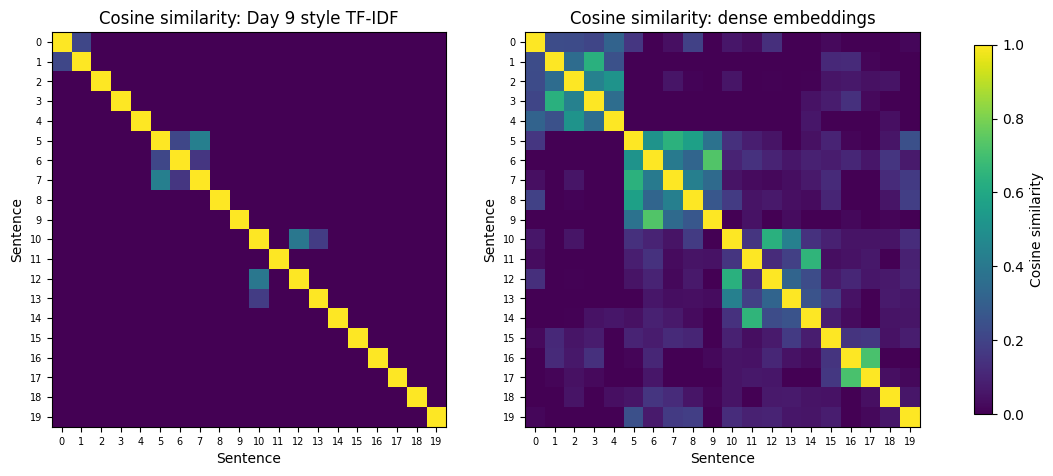

In [6]:
rows = []
for i, j in itertools.combinations(range(20), 2):
    rows.append({"i": i, "j": j, "tfidf": tfidf_sim[i,j], "embedding": emb_sim[i,j],
                 "gap": emb_sim[i,j]-tfidf_sim[i,j], "same_topic": true_labels[i]==true_labels[j]})
pairs = pd.DataFrame(rows)
for name, m in [("same-topic", pairs.same_topic), ("different-topic", ~pairs.same_topic)]:
    print(f"Mean similarity, {name:15s} pairs -> TF-IDF: {pairs[m].tfidf.mean():.3f} | Embedding: {pairs[m].embedding.mean():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, M, t in [(ax[0], tfidf_sim, "Day 9 style TF-IDF"), (ax[1], emb_sim, "dense embeddings")]:
    im = a.imshow(M, cmap="viridis", vmin=0, vmax=1)
    a.set_title(f"Cosine similarity: {t}"); a.set_xlabel("Sentence"); a.set_ylabel("Sentence")
    a.set_xticks(range(20)); a.set_yticks(range(20))
    a.tick_params(labelsize=7)
plt.colorbar(im, ax=ax, label="Cosine similarity", shrink=0.8)
plt.savefig("day13_heatmaps.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Five paraphrase pairs: TF-IDF low, embedding high

A [6]: Pilots fly the airplane across the ocean
B [9]: Aviators cross the sea in aircraft
   TF-IDF = 0.000  |  Embedding = 0.730  (gap +0.730)

A [16]: Developers write code to build mobile apps
B [17]: Programmers create software for smartphones
   TF-IDF = 0.000  |  Embedding = 0.715  (gap +0.715)

A [11]: Bake the bread in a hot oven
B [14]: Loaves are baked inside a very warm stove
   TF-IDF = 0.000  |  Embedding = 0.653  (gap +0.653)

A [1]: A puppy is a young dog that loves to play
B [3]: Juvenile canines enjoy frolicking and games
   TF-IDF = 0.000  |  Embedding = 0.635  (gap +0.635)

A [5]: The airplane landed at the airport
B [8]: The jet touched down at the terminal
   TF-IDF = 0.000  |  Embedding = 0.570  (gap +0.570)



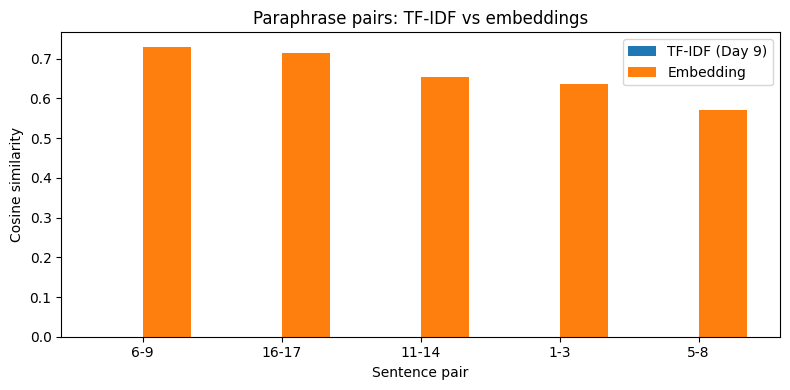

In [7]:
cand = pairs[(pairs.same_topic) & (pairs.tfidf < 0.10) & (pairs.embedding > 0.40)]
top5 = cand.sort_values("gap", ascending=False).head(5)
if len(top5) < 5:   # fallback: largest gaps among same-topic pairs
    top5 = pairs[pairs.same_topic].sort_values("gap", ascending=False).head(5)

for _, r in top5.iterrows():
    i, j = int(r.i), int(r.j)
    print(f"A [{i}]: {sentences[i]}\nB [{j}]: {sentences[j]}")
    print(f"   TF-IDF = {r.tfidf:.3f}  |  Embedding = {r.embedding:.3f}  (gap +{r.gap:.3f})\n")

labels = [f"{int(r.i)}-{int(r.j)}" for _, r in top5.iterrows()]
x = np.arange(len(labels)); w = 0.35
plt.figure(figsize=(8, 4))
plt.bar(x - w/2, top5.tfidf, w, label="TF-IDF (Day 9)"); plt.bar(x + w/2, top5.embedding, w, label="Embedding")
plt.xticks(x, labels); plt.xlabel("Sentence pair"); plt.ylabel("Cosine similarity")
plt.title("Paraphrase pairs: TF-IDF vs embeddings"); plt.legend(); plt.tight_layout()
plt.savefig("day13_paraphrase_pairs.png", dpi=150); plt.show()

## 6. `embed_and_recommend()` vs Day 9 `find_similar()`

In [8]:
def embed_and_recommend(query_sentence, corpus_sentences, top_k=3):
    """Return the top_k corpus sentences most semantically similar to the query (embedding cosine similarity)."""
    vecs, _ = get_embeddings([query_sentence] + list(corpus_sentences))
    q, corpus_vecs = vecs[:1], vecs[1:]
    sims = cosine_similarity(q, corpus_vecs)[0]
    best = np.argsort(sims)[::-1][:top_k]
    return [(corpus_sentences[i], round(float(sims[i]), 3)) for i in best]

queries = ["A young dog likes to play",            # Day 9 style query, different words
           "The plane took off from the airport",   # Day 9 query
           "How do I bake a loaf of bread?",
           "Which phone app should I build?"]
for q in queries:
    print("QUERY:", q)
    print(" Day 9 TF-IDF find_similar:")
    for s, sc in find_similar(q, sentences): print(f"    {sc:.3f}  {s}")
    print(" Embedding embed_and_recommend:")
    for s, sc in embed_and_recommend(q, sentences): print(f"    {sc:.3f}  {s}")
    print()

QUERY: A young dog likes to play
 Day 9 TF-IDF find_similar:
    0.598  A puppy is a young dog that loves to play
    0.219  The dog barked at the mailman
    0.000  The wifi router lost its internet connection
 Embedding embed_and_recommend:
    0.808  A puppy is a young dog that loves to play
    0.683  Juvenile canines enjoy frolicking and games
    0.317  Cats and dogs are popular pets

QUERY: The plane took off from the airport
 Day 9 TF-IDF find_similar:
    0.259  The airplane landed at the airport
    0.189  The airport was busy with flights and airplane traffic
    0.000  The wifi router lost its internet connection
 Embedding embed_and_recommend:
    0.825  The airplane landed at the airport
    0.696  The airport was busy with flights and airplane traffic
    0.561  The jet touched down at the terminal

QUERY: How do I bake a loaf of bread?
 Day 9 TF-IDF find_similar:
    0.515  Bake the bread in a hot oven
    0.000  The wifi router lost its internet connection
    0.000  P

## 7. K-means clustering (k=4) and topic verification

Cluster 0 -> majority topic: Aviation
    [Aviation] The airplane landed at the airport
    [Aviation] Pilots fly the airplane across the ocean
    [Aviation] The airport was busy with flights and airplane traffic
    [Aviation] The jet touched down at the terminal
    [Aviation] Aviators cross the sea in aircraft
    [Technology] Neural networks learn patterns from large datasets   <-- does not match original topic
    [Technology] The wifi router lost its internet connection   <-- does not match original topic
Cluster 1 -> majority topic: Cooking
    [Cooking] She cooked pasta with tomato sauce
    [Cooking] Bake the bread in a hot oven
    [Cooking] The chef cooked a delicious tomato soup
    [Cooking] Cooking pasta takes ten minutes in boiling water
    [Cooking] Loaves are baked inside a very warm stove
Cluster 2 -> majority topic: Animals
    [Animals] The dog barked at the mailman
    [Animals] A puppy is a young dog that loves to play
    [Animals] Cats and dogs are popular pet

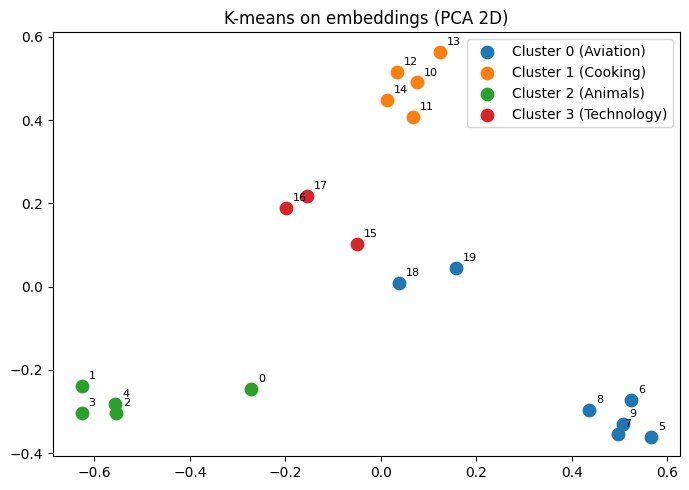

In [9]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(emb)
pred = km.labels_
mapping = {c: np.bincount(true_labels[pred == c], minlength=4).argmax() for c in range(4)}
mapped = np.array([mapping[c] for c in pred])
acc = (mapped == true_labels).mean(); ari = adjusted_rand_score(true_labels, pred)

for c in range(4):
    print(f"Cluster {c} -> majority topic: {topics[mapping[c]]}")
    for idx in np.where(pred == c)[0]:
        flag = "" if mapped[idx] == true_labels[idx] else "   <-- does not match original topic"
        print(f"    [{topics[true_labels[idx]]}] {sentences[idx]}{flag}")
print(f"\nCluster/topic agreement: {acc*100:.0f}% | Adjusted Rand Index: {ari:.3f}")

pts = PCA(n_components=2).fit_transform(emb)
plt.figure(figsize=(7, 5))
for c in range(4):
    m = pred == c
    plt.scatter(pts[m,0], pts[m,1], s=80, label=f"Cluster {c} ({topics[mapping[c]]})")
for i, (px, py) in enumerate(pts): plt.annotate(str(i), (px, py), textcoords="offset points", xytext=(5,5), fontsize=8)
plt.title("K-means on embeddings (PCA 2D)"); plt.legend(); plt.tight_layout()
plt.savefig("day13_clusters.png", dpi=150); plt.show()

## 8. Embedding time and estimated cost (20-sentence batch)

In [10]:
print(f"Model: {MODEL} (local, free)")
print(f"Total embedding generation time: {elapsed:.3f} s")
print(f"Approx. tokens: {total_tokens}")
print(f"Actual cost: ${local_cost:.2f}")
print(f"Estimated OpenAI text-embedding-3-small cost for this batch: ${est_openai_cost:.8f} (${OPENAI_PRICE_PER_1M_TOKENS} per 1M tokens)")

Model: all-MiniLM-L6-v2 (local, free)
Total embedding generation time: 0.379 s
Approx. tokens: 157
Actual cost: $0.00
Estimated OpenAI text-embedding-3-small cost for this batch: $0.00000314 ($0.02 per 1M tokens)


## 9. Sparse TF-IDF vs dense embeddings

**TF-IDF (sparse)** gives every sentence a vector with one dimension per vocabulary word (36 in Day 9, mostly zeros). Each value only says how important that exact word is in this document compared with the rest of the corpus. So it encodes *which words appear and how rare they are*. Words are independent axes: "dog" and "puppy" are as unrelated as "dog" and "airplane", which is why Day 9 gave dog vs puppy a score of **0.000**. Two sentences with the same meaning but different words share no non-zero dimensions, so their cosine similarity is near 0. It also ignores word order and context.

**Dense embeddings** map each sentence to a fixed-length vector (384 numbers here; OpenAI's model uses 1536) where every dimension carries information. A neural network trained on huge amounts of text learned these coordinates, so they encode *meaning*: topic, context and how words are used. Sentences used in similar contexts end up close together, even with zero shared vocabulary.

**Why embeddings generalise across vocabulary:** the model has learned that "puppy" and "young dog", "jet touched down" and "airplane landed", or "baked in an oven" and "warmed in a stove" appear in similar situations, so it places them near each other. Cosine similarity then measures similarity of meaning instead of overlap of spelling. That is why the paraphrase pairs score low with TF-IDF but high with embeddings, and why K-means on embeddings recovers the four topics.

**Trade-offs:** TF-IDF is free, instant and transparent, and is excellent for exact keyword matching. Embeddings cost time and money per call and are harder to interpret, but they handle synonyms and paraphrases, which makes them better for semantic search, recommendation, clustering and RAG.